# DeepDerma LabOps — Model Training Notebook

This notebook documents the training and evaluation workflow for three image-classification models used in the DeepDerma project: **DenseNet201, ResNet101, and EfficientNetB0**. It uses TensorFlow/Keras transfer learning, validation, model fine-tuning, and classification metrics.

> **Important:** This is an experimental educational project, not a medical diagnostic tool. Predictions must not be used to diagnose or treat a skin condition.

## Before you run it

- **Environment:** The existing code is designed for Google Colab and uses `/content/` paths plus Colab upload/download helpers.
- **Dataset:** The dataset is not included in this repository. Obtain it separately and upload the ZIP file when prompted. Follow the folder structure expected by the setup cells below.
- **Classes:** The notebook expects these four class labels: Actinic keratosis, Atopic Dermatitis, Benign keratosis, and Dermatofibroma.
- **Dependencies:** TensorFlow/Keras, NumPy, scikit-learn, Matplotlib, and Seaborn are used in the workflow. Google Colab normally provides many of these.
- **Reproducibility:** Runtime, hardware, dataset version, and random variation can affect results. Run the cells in order and review the generated evaluation reports rather than assuming saved outputs will reproduce exactly.

## Workflow overview

1. Upload and extract the dataset, then inspect its folders.
2. Prepare image generators and preprocessing.
3. Train and evaluate DenseNet201; then fine-tune and evaluate it.
4. Prepare the ResNet101 workflow, train/evaluate, and fine-tune.
5. Prepare the EfficientNetB0 workflow, train/evaluate, and fine-tune.
6. Save trained model files from the Colab runtime.

The code cells below are retained from the original notebook; this copy adds documentation and section headings without intentionally changing the model-training code.


## 1. Dataset upload and inspection

Upload the dataset ZIP in Colab, extract it, and inspect the resulting directories. Check that the train/validation folders and class subfolders match the expected layout before training.


In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [2]:

import os

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)
    print(f"Size: {os.path.getsize(filename) / (1024 * 1024):.2f} MB")


Uploaded files:
archive.zip
Size: 80.38 MB


In [3]:
import os
import zipfile

zip_files = [f for f in os.listdir("/content") if f.lower().endswith(".zip")]

print("ZIP files found:", zip_files)

if not zip_files:
    raise FileNotFoundError("No ZIP file found in /content.")

zip_path = os.path.join("/content", zip_files[0])
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("\nExtraction completed!")
print("Extracted to:", extract_path)

ZIP files found: ['archive.zip']

Extraction completed!
Extracted to: /content/dataset


In [4]:
for root, dirs, files in os.walk("/content/dataset"):
    level = root.replace("/content/dataset", "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    if level < 3:
        for filename in files[:5]:
            print(f"{indent}    {filename}")

    if level == 3:
        dirs[:] = []

dataset/
    Split_smol/
        val/
            Atopic Dermatitis/
            Benign keratosis/
            Dermatofibroma/
            Actinic keratosis/
        train/
            Atopic Dermatitis/
            Benign keratosis/
            Dermatofibroma/
            Actinic keratosis/


## 2. Image loading and preprocessing

The setup defines the image size, batch size, class order, and data generators. Training augmentation is used to vary training examples; validation data should remain representative of the held-out validation split.


In [5]:
import os

base_dir = "/content/dataset/Split_smol"
splits = ["train", "val"]
classes = [
    "Actinic keratosis",
    "Atopic Dermatitis",
    "Benign keratosis",
    "Dermatofibroma"
]

for split in splits:
    print(f"\n{split.upper()} DATASET")
    total = 0

    for class_name in classes:
        folder = os.path.join(base_dir, split, class_name)

        if not os.path.isdir(folder):
            print(f"  {class_name}: FOLDER NOT FOUND")
            continue

        image_count = sum(
            1 for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
        )

        print(f"  {class_name}: {image_count} images")
        total += image_count

    print(f"  Total images: {total}")


TRAIN DATASET
  Actinic keratosis: 80 images
  Atopic Dermatitis: 81 images
  Benign keratosis: 80 images
  Dermatofibroma: 80 images
  Total images: 321

VAL DATASET
  Actinic keratosis: 20 images
  Atopic Dermatitis: 21 images
  Benign keratosis: 20 images
  Dermatofibroma: 20 images
  Total images: 81


In [6]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Dataset paths
train_dir = "/content/dataset/Split_smol/train"
val_dir = "/content/dataset/Split_smol/val"

# Keep class order consistent throughout the project
selected_classes = [
    "Actinic keratosis",
    "Atopic Dermatitis",
    "Benign keratosis",
    "Dermatofibroma"
]

# Verify folders exist
for folder in [train_dir, val_dir]:
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Dataset folder not found: {folder}")

# Training images: augmentation helps reduce overfitting
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode="nearest"
)

# Validation images: no augmentation
val_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=16,
    classes=selected_classes,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=16,
    classes=selected_classes,
    class_mode="categorical",
    shuffle=False
)

print("\nClass mapping:", train_generator.class_indices)
print("Training images:", train_generator.samples)
print("Validation images:", val_generator.samples)

# Inspect one batch
images, labels = next(train_generator)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image value range:", float(images.min()), "to", float(images.max()))

Found 321 images belonging to 4 classes.
Found 81 images belonging to 4 classes.

Class mapping: {'Actinic keratosis': 0, 'Atopic Dermatitis': 1, 'Benign keratosis': 2, 'Dermatofibroma': 3}
Training images: 321
Validation images: 81
Image batch shape: (16, 224, 224, 3)
Label batch shape: (16, 4)
Image value range: 0.0 to 1.0


## 3. DenseNet201 — transfer learning and fine-tuning

The following cells build a classifier on a pretrained DenseNet201 backbone, train the classification head, evaluate predictions with classification metrics/confusion matrix, then fine-tune selected backbone layers with a lower learning rate. Checkpointing and training callbacks help save the best model and limit unhelpful training.


In [8]:
import tensorflow as tf
from tensorflow.keras.applications import DenseNet201
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    BatchNormalization,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Four output classes
num_classes = len(selected_classes)

# Load ImageNet-pretrained DenseNet201
base_model = DenseNet201(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# First stage: freeze the pretrained feature extractor
base_model.trainable = False

inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)

outputs = Dense(num_classes, activation="softmax")(x)

model = Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print("\nTrainable parameters:",
      sum(tf.size(v).numpy() for v in model.trainable_variables))
print("Output classes:", selected_classes)

74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 7, 7, 1920)     │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1920)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1920)           │         7,680 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       491,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,822,468 (71.80 MB)

 Trainable params: 496,644 (1.89 MB)

 Non-trainable params: 18,325,824 (69.91 MB)


Trainable parameters: 496644
Output classes: ['Actinic keratosis', 'Atopic Dermatitis', 'Benign keratosis', 'Dermatofibroma']


In [9]:
import os
import tensorflow as tf
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# Save checkpoints in a dedicated folder
checkpoint_dir = "/content/deepderma_checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_path = os.path.join(
    checkpoint_dir,
    "densenet201_best.keras"
)

callbacks = [
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        mode="min",
        verbose=1
    )
]

print("Checkpoint path:", checkpoint_path)
print("Callbacks configured:", len(callbacks))

Checkpoint path: /content/deepderma_checkpoints/densenet201_best.keras
Callbacks configured: 3


In [10]:
history = model.fit(
    train_generator,
    epochs=15,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3139 - loss: 1.6887
Epoch 1: val_loss improved from None to 1.25642, saving model to /content/deepderma_checkpoints/densenet201_best.keras

Epoch 1: finished saving model to /content/deepderma_checkpoints/densenet201_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 130s 4s/step - accuracy: 0.3583 - loss: 1.5263 - val_accuracy: 0.3333 - val_loss: 1.2564 - learning_rate: 1.0000e-04
Epoch 2/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - accuracy: 0.5390 - loss: 1.0871
Epoch 2: val_loss improved from 1.25642 to 0.95687, saving model to /content/deepderma_checkpoints/densenet201_best.keras

Epoch 2: finished saving model to /content/deepderma_checkpoints/densenet201_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 451ms/step - accuracy: 0.5826 - loss: 1.0050 - val_accuracy: 0.6420 - val_loss: 0.9569 - learning_rate: 1.0000e-04
Epoch 3/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step - accuracy: 0.6704 - loss: 0.8108
Epoch 3: val_loss improved from 0.956

6/6 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.8765 - loss: 0.3635
6/6 ━━━━━━━━━━━━━━━━━━━━ 43s 4s/step

Validation loss: 0.3635
Validation accuracy: 87.6543%

Classification report:
                   precision    recall  f1-score   support

Actinic keratosis     1.0000    0.7000    0.8235        20
Atopic Dermatitis     0.9545    1.0000    0.9767        21
 Benign keratosis     0.9474    0.9000    0.9231        20
   Dermatofibroma     0.6923    0.9000    0.7826        20

         accuracy                         0.8765        81
        macro avg     0.8986    0.8750    0.8765        81
     weighted avg     0.8992    0.8765    0.8777        81



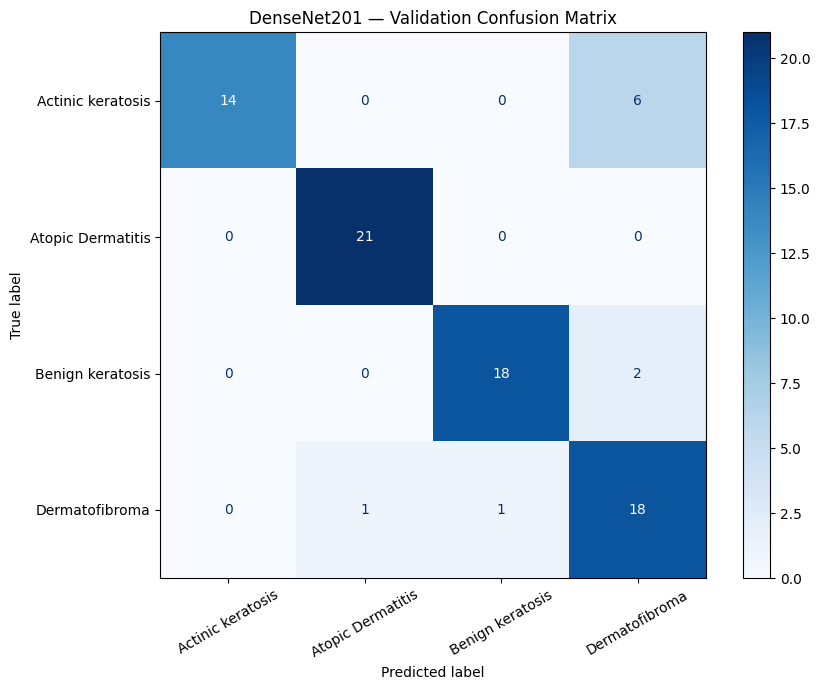

In [11]:

import os
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

checkpoint_path = (
    "/content/deepderma_checkpoints/densenet201_best.keras"
)

# Load the best saved checkpoint
best_model = tf.keras.models.load_model(checkpoint_path)

# Reset validation generator before collecting predictions
val_generator.reset()

val_loss, val_accuracy = best_model.evaluate(
    val_generator,
    verbose=1
)

# Predict validation classes
val_generator.reset()
probabilities = best_model.predict(val_generator, verbose=1)
predicted_classes = np.argmax(probabilities, axis=1)
true_classes = val_generator.classes

print(f"\nValidation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4%}")

print("\nClassification report:")
print(classification_report(
    true_classes,
    predicted_classes,
    labels=list(range(len(selected_classes))),
    target_names=selected_classes,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(
    true_classes,
    predicted_classes,
    labels=list(range(len(selected_classes)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=selected_classes
)

fig, ax = plt.subplots(figsize=(9, 7))
display.plot(ax=ax, cmap="Blues", xticks_rotation=30, values_format="d")
plt.title("DenseNet201 — Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [12]:

from google.colab import files
import os

checkpoint_path = (
    "/content/deepderma_checkpoints/densenet201_best.keras"
)

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError("Best DenseNet201 checkpoint not found.")

print(
    "Model size:",
    round(os.path.getsize(checkpoint_path) / (1024 * 1024), 2),
    "MB"
)

files.download(checkpoint_path)


Model size: 77.99 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

import os
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# Start from the best baseline checkpoint
baseline_path = (
    "/content/deepderma_checkpoints/densenet201_best.keras"
)

fine_tune_model = tf.keras.models.load_model(baseline_path)

# Unfreeze the feature extractor, then freeze most layers.
# Fine-tune only the final 50 layers.
base = fine_tune_model.get_layer("densenet201")
base.trainable = True

for layer in base.layers[:-50]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stability
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

fine_tune_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_dir = "/content/deepderma_finetuned"
os.makedirs(fine_tune_dir, exist_ok=True)

fine_tune_callbacks = [
    ModelCheckpoint(
        os.path.join(fine_tune_dir, "densenet201_finetuned_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        mode="min",
        verbose=1
    )
]

print("Fine-tuning model prepared.")
print("Trainable parameters:",
      sum(tf.size(v).numpy()
          for v in fine_tune_model.trainable_variables))
print("Baseline checkpoint remains unchanged.")


Fine-tuning model prepared.
Trainable parameters: 2360324
Baseline checkpoint remains unchanged.


In [14]:

fine_tune_history = fine_tune_model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator,
    callbacks=fine_tune_callbacks,
    verbose=1
)


Epoch 1/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9166 - loss: 0.2447
Epoch 1: val_loss improved from None to 0.35623, saving model to /content/deepderma_finetuned/densenet201_finetuned_best.keras

Epoch 1: finished saving model to /content/deepderma_finetuned/densenet201_finetuned_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 117s 4s/step - accuracy: 0.9003 - loss: 0.2738 - val_accuracy: 0.8765 - val_loss: 0.3562 - learning_rate: 1.0000e-05
Epoch 2/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - accuracy: 0.8685 - loss: 0.3549
Epoch 2: val_loss improved from 0.35623 to 0.34535, saving model to /content/deepderma_finetuned/densenet201_finetuned_best.keras

Epoch 2: finished saving model to /content/deepderma_finetuned/densenet201_finetuned_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 457ms/step - accuracy: 0.8660 - loss: 0.3457 - val_accuracy: 0.8765 - val_loss: 0.3453 - learning_rate: 1.0000e-05
Epoch 3/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - accuracy: 0.9042 - loss: 0.3076
Epoc

6/6 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.8889 - loss: 0.3041
6/6 ━━━━━━━━━━━━━━━━━━━━ 44s 4s/step

Fine-tuned validation loss: 0.3041
Fine-tuned validation accuracy: 88.8889%

Fine-tuned classification report:
                   precision    recall  f1-score   support

Actinic keratosis     1.0000    0.7000    0.8235        20
Atopic Dermatitis     0.9545    1.0000    0.9767        21
 Benign keratosis     0.9500    0.9500    0.9500        20
   Dermatofibroma     0.7200    0.9000    0.8000        20

         accuracy                         0.8889        81
        macro avg     0.9061    0.8875    0.8876        81
     weighted avg     0.9067    0.8889    0.8887        81



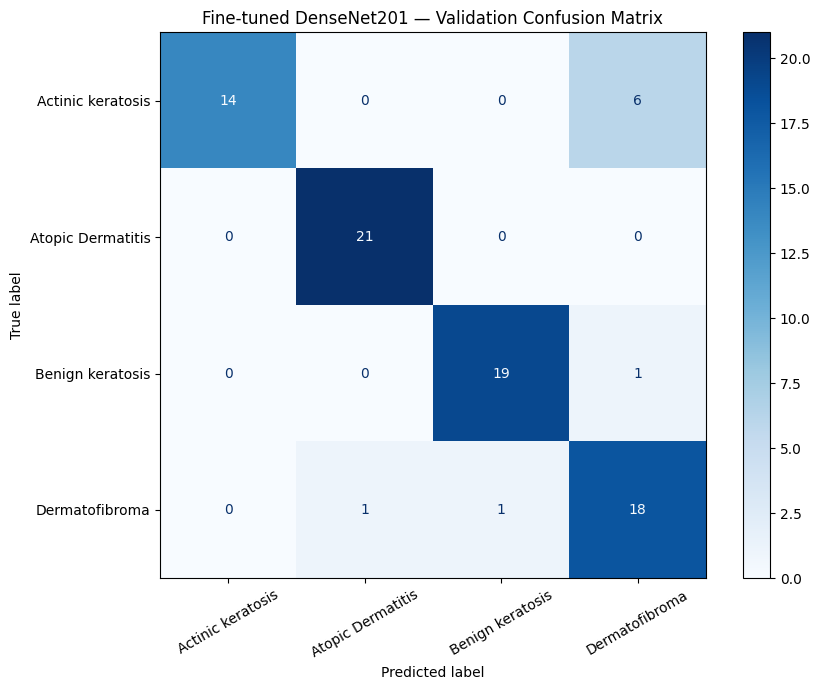

In [15]:

import os
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fine_tuned_path = (
    "/content/deepderma_finetuned/"
    "densenet201_finetuned_best.keras"
)

if not os.path.exists(fine_tuned_path):
    raise FileNotFoundError("Fine-tuned checkpoint not found.")

best_fine_tuned = tf.keras.models.load_model(fine_tuned_path)

val_generator.reset()
fine_loss, fine_accuracy = best_fine_tuned.evaluate(
    val_generator, verbose=1
)

val_generator.reset()
fine_probabilities = best_fine_tuned.predict(
    val_generator, verbose=1
)

fine_predictions = np.argmax(fine_probabilities, axis=1)
true_classes = val_generator.classes

print(f"\nFine-tuned validation loss: {fine_loss:.4f}")
print(f"Fine-tuned validation accuracy: {fine_accuracy:.4%}")

print("\nFine-tuned classification report:")
print(classification_report(
    true_classes,
    fine_predictions,
    labels=list(range(len(selected_classes))),
    target_names=selected_classes,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(
    true_classes,
    fine_predictions,
    labels=list(range(len(selected_classes)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=selected_classes
)

fig, ax = plt.subplots(figsize=(9, 7))
display.plot(ax=ax, cmap="Blues", xticks_rotation=30, values_format="d")
plt.title("Fine-tuned DenseNet201 — Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [16]:

from google.colab import files
import os

fine_tuned_path = (
    "/content/deepderma_finetuned/"
    "densenet201_finetuned_best.keras"
)

if not os.path.exists(fine_tuned_path):
    raise FileNotFoundError("Fine-tuned model was not found.")

size_mb = os.path.getsize(fine_tuned_path) / (1024 * 1024)
print(f"Fine-tuned model size: {size_mb:.2f} MB")

files.download(fine_tuned_path)


Fine-tuned model size: 92.19 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. ResNet101 — baseline and fine-tuning

This section prepares the image pipeline for ResNet101, trains the model, evaluates class-level results, and performs a fine-tuning stage. ResNet-specific preprocessing is defined where needed; use the preprocessing expected by the chosen pretrained architecture.


In [17]:
import os
import tensorflow as tf

DATA_DIR = "/content/dataset/Split_smol"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "val")

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))
print("Training folder exists:", os.path.isdir(TRAIN_DIR))
print("Validation folder exists:", os.path.isdir(VAL_DIR))

print("\nTraining classes:", sorted(os.listdir(TRAIN_DIR)))
print("Validation classes:", sorted(os.listdir(VAL_DIR)))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training folder exists: True
Validation folder exists: True

Training classes: ['Actinic keratosis', 'Atopic Dermatitis', 'Benign keratosis', 'Dermatofibroma']
Validation classes: ['Actinic keratosis', 'Atopic Dermatitis', 'Benign keratosis', 'Dermatofibroma']


In [18]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("\nClass indices:", train_generator.class_indices)
print("Training images:", train_generator.samples)
print("Validation images:", val_generator.samples)
print("Image batch shape:", train_generator[0][0].shape)
print("Label batch shape:", train_generator[0][1].shape)

Found 321 images belonging to 4 classes.
Found 81 images belonging to 4 classes.

Class indices: {'Actinic keratosis': 0, 'Atopic Dermatitis': 1, 'Benign keratosis': 2, 'Dermatofibroma': 3}
Training images: 321
Validation images: 81
Image batch shape: (16, 224, 224, 3)
Label batch shape: (16, 4)


In [19]:
import os
import tensorflow as tf
from tensorflow.keras.applications import ResNet101
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    BatchNormalization,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# Save checkpoints in Google Colab
CHECKPOINT_DIR = "/content/deepderma_resnet101"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "resnet101_best.keras"
)

# Load the pretrained ResNet101 backbone
base_model = ResNet101(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the backbone for baseline training
base_model.trainable = False

# Add a four-class classification head
inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
outputs = Dense(4, activation="softmax")(x)

model = Model(inputs=inputs, outputs=outputs)

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Callbacks
callbacks = [
    ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# Show model details
model.summary()

print("\nCheckpoint path:", BEST_MODEL_PATH)
print("Trainable parameters:",
      sum(tf.keras.backend.count_params(w)
          for w in model.trainable_weights))

171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet101 (Functional)          │ (None, 7, 7, 2048)     │    42,658,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,191,940 (164.76 MB)

 Trainable params: 529,668 (2.02 MB)

 Non-trainable params: 42,662,272 (162.74 MB)


Checkpoint path: /content/deepderma_resnet101/resnet101_best.keras
Trainable parameters: 529668


In [20]:
history_resnet101 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 649ms/step - accuracy: 0.2623 - loss: 1.4257
Epoch 1: val_loss improved from None to 1.52612, saving model to /content/deepderma_resnet101/resnet101_best.keras

Epoch 1: finished saving model to /content/deepderma_resnet101/resnet101_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.2928 - loss: 1.3916 - val_accuracy: 0.2469 - val_loss: 1.5261 - learning_rate: 1.0000e-04
Epoch 2/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.4067 - loss: 1.3055
Epoch 2: val_loss improved from 1.52612 to 1.48851, saving model to /content/deepderma_resnet101/resnet101_best.keras

Epoch 2: finished saving model to /content/deepderma_resnet101/resnet101_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 432ms/step - accuracy: 0.4050 - loss: 1.3078 - val_accuracy: 0.2469 - val_loss: 1.4885 - learning_rate: 1.0000e-04
Epoch 3/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 273ms/step - accuracy: 0.3744 - loss: 1.2690
Epoch 3: val_loss improved from 1.48851 to 1.46960,

In [21]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

# Load the best saved checkpoint
resnet101_best = tf.keras.models.load_model(
    "/content/deepderma_resnet101/resnet101_best.keras",
    compile=False
)

# Generate predictions on the validation set
val_generator.reset()

pred_probs = resnet101_best.predict(
    val_generator,
    verbose=1
)

y_pred = np.argmax(pred_probs, axis=1)
y_true = val_generator.classes

class_names = list(val_generator.class_indices.keys())

print("\nValidation accuracy:",
      round(np.mean(y_pred == y_true) * 100, 2), "%")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))

6/6 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step

Validation accuracy: 49.38 %

Classification report:
                   precision    recall  f1-score   support

Actinic keratosis     0.3810    0.8000    0.5161        20
Atopic Dermatitis     0.5385    0.6667    0.5957        21
 Benign keratosis     0.8333    0.2500    0.3846        20
   Dermatofibroma     0.7143    0.2500    0.3704        20

         accuracy                         0.4938        81
        macro avg     0.6168    0.4917    0.4667        81
     weighted avg     0.6158    0.4938    0.4683        81


Confusion matrix:
[[16  3  1  0]
 [ 7 14  0  0]
 [ 9  4  5  2]
 [10  5  0  5]]


In [22]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ResNet101-specific preprocessing
resnet_preprocess = tf.keras.applications.resnet.preprocess_input

resnet_train_datagen = ImageDataGenerator(
    preprocessing_function=resnet_preprocess,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

resnet_val_datagen = ImageDataGenerator(
    preprocessing_function=resnet_preprocess
)

resnet_train_generator = resnet_train_datagen.flow_from_directory(
    "/content/dataset/Split_smol/train",
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

resnet_val_generator = resnet_val_datagen.flow_from_directory(
    "/content/dataset/Split_smol/val",
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    shuffle=False
)

print("Training images:", resnet_train_generator.samples)
print("Validation images:", resnet_val_generator.samples)
print("Class indices:", resnet_train_generator.class_indices)

Found 321 images belonging to 4 classes.
Found 81 images belonging to 4 classes.
Training images: 321
Validation images: 81
Class indices: {'Actinic keratosis': 0, 'Atopic Dermatitis': 1, 'Benign keratosis': 2, 'Dermatofibroma': 3}


In [23]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# Keep this experiment separate from the original
checkpoint_dir = "/content/deepderma_resnet101_preprocessed"
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_path = os.path.join(
    checkpoint_dir,
    "resnet101_best.keras"
)

# Load pretrained ResNet101
base_model = tf.keras.applications.ResNet101(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained backbone for initial training
base_model.trainable = False

# Build the classification head
inputs = layers.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

resnet101_model = models.Model(inputs, outputs)

resnet101_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Training ResNet101 with corrected preprocessing...")
print("Checkpoint:", checkpoint_path)

history_resnet101 = resnet101_model.fit(
    resnet_train_generator,
    validation_data=resnet_val_generator,
    epochs=15,
    callbacks=callbacks
)

Training ResNet101 with corrected preprocessing...
Checkpoint: /content/deepderma_resnet101_preprocessed/resnet101_best.keras
Epoch 1/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 634ms/step - accuracy: 0.3189 - loss: 1.9818
Epoch 1: val_loss improved from None to 1.02692, saving model to /content/deepderma_resnet101_preprocessed/resnet101_best.keras

Epoch 1: finished saving model to /content/deepderma_resnet101_preprocessed/resnet101_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.4174 - loss: 1.6832 - val_accuracy: 0.5802 - val_loss: 1.0269 - learning_rate: 1.0000e-04
Epoch 2/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step - accuracy: 0.6035 - loss: 1.0618
Epoch 2: val_loss improved from 1.02692 to 0.65927, saving model to /content/deepderma_resnet101_preprocessed/resnet101_best.keras

Epoch 2: finished saving model to /content/deepderma_resnet101_preprocessed/resnet101_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 449ms/step - accuracy: 0.6760 - loss: 0.8982 - val_accuracy: 0.7654 - val_

In [24]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

# Load the best corrected-preprocessing checkpoint
resnet101_best = tf.keras.models.load_model(
    "/content/deepderma_resnet101_preprocessed/resnet101_best.keras",
    compile=False
)

# Predict using the matching ResNet101 validation generator
resnet_val_generator.reset()

pred_probs = resnet101_best.predict(
    resnet_val_generator,
    verbose=1
)

y_pred = np.argmax(pred_probs, axis=1)
y_true = resnet_val_generator.classes

class_names = list(resnet_val_generator.class_indices.keys())

print(
    "\nValidation accuracy:",
    round(np.mean(y_pred == y_true) * 100, 2),
    "%"
)

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))

6/6 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step

Validation accuracy: 82.72 %

Classification report:
                   precision    recall  f1-score   support

Actinic keratosis     0.9167    0.5500    0.6875        20
Atopic Dermatitis     0.8750    1.0000    0.9333        21
 Benign keratosis     1.0000    0.9500    0.9744        20
   Dermatofibroma     0.6154    0.8000    0.6957        20

         accuracy                         0.8272        81
        macro avg     0.8518    0.8250    0.8227        81
     weighted avg     0.8520    0.8272    0.8241        81


Confusion matrix:
[[11  0  0  9]
 [ 0 21  0  0]
 [ 0  0 19  1]
 [ 1  3  0 16]]


In [25]:
import os
import tensorflow as tf
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# Load the best model from the corrected-preprocessing experiment
resnet101_finetune = tf.keras.models.load_model(
    "/content/deepderma_resnet101_preprocessed/resnet101_best.keras",
    compile=False
)

# Access the pretrained ResNet101 backbone
base_model = resnet101_finetune.get_layer("resnet101")

# Unfreeze the backbone, then freeze all but its last 50 layers
base_model.trainable = True

for layer in base_model.layers[:-50]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a small learning rate
resnet101_finetune.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Save this experiment separately
finetune_dir = "/content/deepderma_resnet101_finetuned"
os.makedirs(finetune_dir, exist_ok=True)

finetune_callbacks = [
    ModelCheckpoint(
        os.path.join(finetune_dir, "resnet101_finetuned_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Trainable parameters:", sum(
    tf.keras.backend.count_params(w)
    for w in resnet101_finetune.trainable_weights
))

history_resnet101_finetune = resnet101_finetune.fit(
    resnet_train_generator,
    validation_data=resnet_val_generator,
    epochs=10,
    callbacks=finetune_callbacks
)

Trainable parameters: 17452036
Epoch 1/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 860ms/step - accuracy: 0.9029 - loss: 0.2728
Epoch 1: val_loss improved from None to 0.30239, saving model to /content/deepderma_resnet101_finetuned/resnet101_finetuned_best.keras

Epoch 1: finished saving model to /content/deepderma_resnet101_finetuned/resnet101_finetuned_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.9065 - loss: 0.2524 - val_accuracy: 0.8519 - val_loss: 0.3024 - learning_rate: 1.0000e-05
Epoch 2/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step - accuracy: 0.8977 - loss: 0.2748
Epoch 2: val_loss improved from 0.30239 to 0.27909, saving model to /content/deepderma_resnet101_finetuned/resnet101_finetuned_best.keras

Epoch 2: finished saving model to /content/deepderma_resnet101_finetuned/resnet101_finetuned_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 11s 508ms/step - accuracy: 0.9065 - loss: 0.2208 - val_accuracy: 0.8765 - val_loss: 0.2791 - learning_rate: 1.0000e-05
Epoch 3/10
21/21 ━━━━━━━━

In [26]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

# Load the checkpoint with the lowest validation loss
resnet101_finetuned_best = tf.keras.models.load_model(
    "/content/deepderma_resnet101_finetuned/resnet101_finetuned_best.keras",
    compile=False
)

# Generate predictions with the matching ResNet101 preprocessing
resnet_val_generator.reset()

pred_probs = resnet101_finetuned_best.predict(
    resnet_val_generator,
    verbose=1
)

y_pred = np.argmax(pred_probs, axis=1)
y_true = resnet_val_generator.classes
class_names = list(resnet_val_generator.class_indices.keys())

print(
    "\nSaved checkpoint validation accuracy:",
    round(np.mean(y_pred == y_true) * 100, 2),
    "%"
)

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))

6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step

Saved checkpoint validation accuracy: 88.89 %

Classification report:
                   precision    recall  f1-score   support

Actinic keratosis     0.8889    0.8000    0.8421        20
Atopic Dermatitis     0.8750    1.0000    0.9333        21
 Benign keratosis     1.0000    0.9500    0.9744        20
   Dermatofibroma     0.8000    0.8000    0.8000        20

         accuracy                         0.8889        81
        macro avg     0.8910    0.8875    0.8874        81
     weighted avg     0.8908    0.8889    0.8880        81


Confusion matrix:
[[16  0  0  4]
 [ 0 21  0  0]
 [ 1  0 19  0]
 [ 1  3  0 16]]


In [27]:
from google.colab import files

files.download(
    "/content/deepderma_resnet101_finetuned/resnet101_finetuned_best.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. EfficientNetB0 — baseline and fine-tuning

This section trains and evaluates EfficientNetB0 and then runs a fine-tuning stage. Review the classification report and confusion matrix for class-level behavior, not just overall accuracy.


In [28]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# EfficientNetB0 includes rescaling internally
efficientnet_train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

efficientnet_val_datagen = ImageDataGenerator()

# Training data
efficientnet_train_generator = efficientnet_train_datagen.flow_from_directory(
    "/content/dataset/Split_smol/train",
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

# Validation data
efficientnet_val_generator = efficientnet_val_datagen.flow_from_directory(
    "/content/dataset/Split_smol/val",
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    shuffle=False
)

print("TensorFlow:", tf.__version__)
print("Training images:", efficientnet_train_generator.samples)
print("Validation images:", efficientnet_val_generator.samples)
print("Class indices:", efficientnet_train_generator.class_indices)
print(
    "GPU devices:",
    tf.config.list_physical_devices("GPU")
)

Found 321 images belonging to 4 classes.
Found 81 images belonging to 4 classes.
TensorFlow: 2.21.0
Training images: 321
Validation images: 81
Class indices: {'Actinic keratosis': 0, 'Atopic Dermatitis': 1, 'Benign keratosis': 2, 'Dermatofibroma': 3}
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [29]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# Separate checkpoint directory
checkpoint_dir = "/content/deepderma_efficientnetb0"
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_path = os.path.join(
    checkpoint_dir,
    "efficientnetb0_best.keras"
)

# Load pretrained EfficientNetB0
base_model = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained backbone
base_model.trainable = False

# Build the classification head
inputs = layers.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

efficientnetb0_model = models.Model(inputs, outputs)

# Compile
efficientnetb0_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Callbacks
callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Training EfficientNetB0...")
print("Checkpoint:", checkpoint_path)
print("Input shape:", efficientnetb0_model.input_shape)
print("Output shape:", efficientnetb0_model.output_shape)

history_efficientnetb0 = efficientnetb0_model.fit(
    efficientnet_train_generator,
    validation_data=efficientnet_val_generator,
    epochs=15,
    callbacks=callbacks
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training EfficientNetB0...
Checkpoint: /content/deepderma_efficientnetb0/efficientnetb0_best.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Epoch 1/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 873ms/step - accuracy: 0.3166 - loss: 1.9198
Epoch 1: val_loss improved from None to 1.05996, saving model to /content/deepderma_efficientnetb0/efficientnetb0_best.keras

Epoch 1: finished saving model to /content/deepderma_efficientnetb0/efficientnetb0_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.3583 - loss: 1.6945 - val_accuracy: 0.6049 - val_loss: 1.0600 - learning_rate: 1.0000e-04
Epoch 2/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step - accuracy: 0.5889 - loss: 1.1232
Epoch 2: val_loss improved from 1.05996 to 0.86380, saving model to /content/deepderma_efficientnetb0/efficientnetb0_best.keras

Epoch 2: finished saving model to /content/deepderma_efficientnetb0/efficientnetb0_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 326ms

In [30]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

# Load the best saved EfficientNetB0 checkpoint
efficientnetb0_best = tf.keras.models.load_model(
    "/content/deepderma_efficientnetb0/efficientnetb0_best.keras",
    compile=False
)

# Generate predictions on the validation dataset
efficientnet_val_generator.reset()

pred_probs = efficientnetb0_best.predict(
    efficientnet_val_generator,
    verbose=1
)

y_pred = np.argmax(pred_probs, axis=1)
y_true = efficientnet_val_generator.classes

class_names = list(
    efficientnet_val_generator.class_indices.keys()
)

# Calculate validation accuracy
accuracy = np.mean(y_pred == y_true) * 100

print("\nSaved EfficientNetB0 validation accuracy:",
      round(accuracy, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step

Saved EfficientNetB0 validation accuracy: 83.95 %

Classification Report:
                   precision    recall  f1-score   support

Actinic keratosis     0.8571    0.6000    0.7059        20
Atopic Dermatitis     0.9130    1.0000    0.9545        21
 Benign keratosis     1.0000    0.9000    0.9474        20
   Dermatofibroma     0.6538    0.8500    0.7391        20

         accuracy                         0.8395        81
        macro avg     0.8560    0.8375    0.8367        81
     weighted avg     0.8567    0.8395    0.8382        81


Confusion Matrix:
[[12  0  0  8]
 [ 0 21  0  0]
 [ 1  0 18  1]
 [ 1  2  0 17]]


In [32]:

import os
import tensorflow as tf
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# Load the best baseline checkpoint
efficientnetb0_model = tf.keras.models.load_model(
    "/content/deepderma_efficientnetb0/efficientnetb0_best.keras",
    compile=False
)

# Identify the pretrained EfficientNetB0 backbone
base_model = efficientnetb0_model.get_layer("efficientnetb0")

# Freeze the backbone, then unfreeze its last 50 layers
base_model.trainable = True

for layer in base_model.layers[:-50]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a lower learning rate
efficientnetb0_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Save fine-tuned model separately
checkpoint_dir = "/content/deepderma_efficientnetb0_finetuned"
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_path = os.path.join(
    checkpoint_dir,
    "efficientnetb0_finetuned_best.keras"
)

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Trainable parameters:",
      sum(
          int(tf.keras.backend.count_params(w))
          for w in efficientnetb0_model.trainable_weights
      ))

print("Starting EfficientNetB0 fine-tuning...")
print("Checkpoint:", checkpoint_path)

history_efficientnetb0_finetuned = efficientnetb0_model.fit(
    efficientnet_train_generator,
    validation_data=efficientnet_val_generator,
    epochs=10,
    callbacks=callbacks
)


Trainable parameters: 2840212
Starting EfficientNetB0 fine-tuning...
Checkpoint: /content/deepderma_efficientnetb0_finetuned/efficientnetb0_finetuned_best.keras
Epoch 1/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 840ms/step - accuracy: 0.8898 - loss: 0.2431
Epoch 1: val_loss improved from None to 0.37948, saving model to /content/deepderma_efficientnetb0_finetuned/efficientnetb0_finetuned_best.keras

Epoch 1: finished saving model to /content/deepderma_efficientnetb0_finetuned/efficientnetb0_finetuned_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.8816 - loss: 0.2660 - val_accuracy: 0.8395 - val_loss: 0.3795 - learning_rate: 1.0000e-05
Epoch 2/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.8942 - loss: 0.2863
Epoch 2: val_loss improved from 0.37948 to 0.37445, saving model to /content/deepderma_efficientnetb0_finetuned/efficientnetb0_finetuned_best.keras

Epoch 2: finished saving model to /content/deepderma_efficientnetb0_finetuned/efficientnetb0_finetuned_best.keras
2

In [33]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

checkpoint_path = (
    "/content/deepderma_efficientnetb0_finetuned/"
    "efficientnetb0_finetuned_best.keras"
)

efficientnetb0_finetuned = tf.keras.models.load_model(
    checkpoint_path,
    compile=False
)

efficientnet_val_generator.reset()

pred_probs = efficientnetb0_finetuned.predict(
    efficientnet_val_generator,
    verbose=1
)

y_pred = np.argmax(pred_probs, axis=1)
y_true = efficientnet_val_generator.classes
class_names = list(efficientnet_val_generator.class_indices.keys())

print(
    "\nFine-tuned EfficientNetB0 validation accuracy:",
    f"{np.mean(y_pred == y_true) * 100:.2f}%"
)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))


6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step

Fine-tuned EfficientNetB0 validation accuracy: 88.89%

Classification Report:
                   precision    recall  f1-score   support

Actinic keratosis     0.8889    0.8000    0.8421        20
Atopic Dermatitis     0.9130    1.0000    0.9545        21
 Benign keratosis     1.0000    0.9000    0.9474        20
   Dermatofibroma     0.7727    0.8500    0.8095        20

         accuracy                         0.8889        81
        macro avg     0.8937    0.8875    0.8884        81
     weighted avg     0.8939    0.8889    0.8892        81


Confusion Matrix:
[[16  0  0  4]
 [ 0 21  0  0]
 [ 1  0 18  1]
 [ 1  2  0 17]]


In [34]:

from google.colab import files

files.download(
    "/content/deepderma_efficientnetb0_finetuned/"
    "efficientnetb0_finetuned_best.keras"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Interpreting and using the results

- Compare all three models on the same held-out validation data where possible.
- Review precision, recall, F1-score, and the confusion matrix to identify classes that are often confused.
- Avoid comparing scores produced with different data splits or preprocessing as if they were directly equivalent.
- Model files are generated in the Colab runtime; they are not included in this notebook or the public Git repository.
- Before using results in a portfolio write-up, rerun the notebook and report only metrics you can verify from that run.

## Limitations

This notebook demonstrates an educational computer-vision workflow. Dataset composition, class imbalance, image quality, and external validation may limit generalization. It is not validated for clinical use and must not be presented as a medical diagnosis system.
